# Wisconsin Representatives Per Diem Analysis
##### *Group Members*: Calvin O'Connor, Taven Hatleli, David Reeh, Kat Klopotek
##### Date: **November 5, 2026**

**Objective**: Analyze the historical per diem payments from Wisconsin representatives and investigate the relationships between total 
compensation, distance from Madison, committee assignments, days claimed, and political party. The analysis will lead to the development of a
per diem allowance formula to potentially implement in the future. 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import fsolve
from scipy.optimize import curve_fit
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
%matplotlib inline


## Data Reading

Our analysis uses the two datasets provided to us, through which we gather historical Wisconsin Assembly per diem payments and information about representatives, including their travel distance to Madison, committee assignments, and political party. 

In [2]:
#reads in file as 
repsData = pd.read_csv('WI_reps_perdiem_data.csv', thousands=",", encoding='windows-1252') 


In [3]:
print(repsData.columns)

Index(['NAME', 'PARTY', 'DISTRICT', 'DAYS CLAIMED', 'TOTAL'], dtype='str')


In [4]:
#reads in file using pandas, fixes some white space issue in the days claimed column i lost sleep over and spent WAYYYYYY too long on
#also probably a much better way exists but i kinda like that pandas uses the first row as a name for the columns and thats kinda convenient
repsData = pd.read_csv('WI_reps_perdiem_data.csv', thousands=",", encoding='windows-1252') 
repsData.columns = repsData.columns.str.replace("\xa0", " ").str.strip()

#gets rid of the last row 
repsData = repsData.iloc[:-1]
#formats the total column to be just a float number 
repsData["TOTAL"] = repsData["TOTAL"].str.replace("$", "").str.replace(",", "").astype(float)

In [5]:
commiteeData = pd.read_excel('Wisconsin_Assembly_2025_26_Committee_and_Hometown_Data.xlsx')
commiteeData.head()

,Assembly District,Representative,Party,Hometown,Approx. Distance to Madison (miles),Committee Count,Committee Assignments
0,15,Adam Neylon,R,Pewaukee,65,5,"Energy & Utilities; Health, Aging & Long-Term ..."
1,39,Alex Dallman,R,Green Lake,85,1,Joint Committee on Finance
2,81,Alex Joers,D,Middleton,10,4,Colleges & Universities; Small Business Develo...
3,90,Amaad Rivera-Wagner,D,Green Bay,145,2,Consumer Protection; Local Government
4,32,Amanda Nedweski,R,Pleasant Prairie,105,2,Colleges & Universities; Government Operations...


## Data Manipulation

In [6]:
#turn district to an integer
repsData['DISTRICT'] = repsData['DISTRICT'].astype(int)
commiteeData['Assembly District'] = commiteeData['Assembly District'].astype(int)

#merge the two datasets based on Assembly district, cant sort because they have different # of rows
repsData = pd.merge(
    repsData,
    commiteeData[['Assembly District',
                  'Approx. Distance to Madison (miles)',
                  'Committee Count',
                 'Committee Assignments']
],
    left_on='DISTRICT',
    right_on='Assembly District',
    how='left',
    validate='one_to_one'
)

#renaming some columns
repsData = repsData.rename(columns={
    'DAYS CLAIMED': 'DAYS_CLAIMED',
    'Approx. Distance to Madison (miles)': 'DISTANCE',
    'Committee Count': 'COMMITTEE_COUNT',
    'Committee Assignments': 'COMMITTEE_ASSIGNMENTS'
})

#removing the duplicate district column and sorting everything by district
repsData = repsData.drop(columns='Assembly District')
repsData = repsData.sort_values(by='DISTRICT').reset_index(drop=True)

#Adding Per Diem/Day Column
repsData['PER_DIEM/DAY'] = round(repsData['TOTAL'] / repsData['DAYS_CLAIMED'], 2)

repsData.head(100)

,NAME,PARTY,DISTRICT,DAYS_CLAIMED,TOTAL,DISTANCE,COMMITTEE_COUNT,COMMITTEE_ASSIGNMENTS,PER_DIEM/DAY
0,"Kitchens, Joel",R,1,113.0,15903.0,145,5,"Agriculture; Education; Environment; Health, A...",140.73
1,"Sortwell, Shae",R,2,113.0,15358.0,145,6,Criminal Justice & Public Safety; Energy & Uti...,135.91
2,"Tusler, Ron",R,3,41.0,4531.5,105,5,Commerce; Constitution & Ethics; Insurance; Ju...,110.52
3,"Steffen, David",R,4,106.0,14845.0,150,4,Criminal Justice & Public Safety; Energy & Uti...,140.05
4,"Goeben, Joy",R,5,114.0,15475.5,150,6,Children & Families; Education; Environment; H...,135.75
...,...,...,...,...,...,...,...,...,...
93,"Billings, Jill",D,95,74.0,9107.0,145,3,Agriculture; Children & Families; Tourism,123.07
94,"Johnson, Tara",D,96,92.0,12280.0,145,2,"Agriculture; Health, Aging & Long-Term Care",133.48
95,"Duchow, Cindi",R,97,72.0,7150.0,50,5,Criminal Justice & Public Safety; Education; F...,99.31
96,"Piwowarczyk, Jim",R,98,86.0,9202.0,55,6,Colleges & Universities; Criminal Justice & Pu...,107.00


In [7]:
# Normalize spacing around the semicolons, so we can one-hot encode it
committee_dummies = (
    repsData["COMMITTEE_ASSIGNMENTS"]
    .str.replace(r"\s*;\s*", ";", regex=True)
    .str.strip()
    .str.get_dummies(sep=";")
)

# Get the committee names in an array
committee_names = sorted({c.strip() for c in repsData["COMMITTEE_ASSIGNMENTS"].str.split(";").explode().dropna()})

# Combine Data
repsData = pd.concat([repsData, committee_dummies], axis=1)
repsData = repsData.drop(columns="COMMITTEE_ASSIGNMENTS")

# replace spaces with underscores
repsData.columns = repsData.columns.str.replace(" ", "_")

In [8]:
# Make committee_names a numpy array
committee_names = np.array(committee_names)

# replace spaces with underscores to match the columns
committee_names = np.char.replace(committee_names.astype(str), " ", "_")

print(committee_names)

['Agriculture' 'Assembly_Committee_on_Assembly_Organization'
 'Campaigns_&_Elections' 'Children_&_Families' 'Colleges_&_Universities'
 'Commerce' 'Constitution_&_Ethics' 'Consumer_Protection' 'Corrections'
 'Criminal_Justice_&_Public_Safety' 'Education' 'Energy_&_Utilities'
 'Environment' 'Financial_Institutions'
 'Forestry,_Parks_&_Outdoor_Recreation'
 'Government_Operations,_Accountability_&_Transparency'
 'Health,_Aging_&_Long-Term_Care' 'Housing_&_Real_Estate' 'Insurance'
 'Jobs_&_Economy' 'Joint_Committee_for_Review_of_Administrative_Rules'
 'Joint_Committee_on_Employment_Relations' 'Joint_Committee_on_Finance'
 'Joint_Committee_on_Information_Policy_&_Technology'
 'Joint_Committee_on_Legislative_Organization' 'Joint_Legislative_Audit'
 'Joint_Legislative_Council'
 'Joint_Review_Committee_on_Criminal_Penalties'
 'Joint_Survey_Committee_on_Retirement_Systems'
 'Joint_Survey_Committee_on_Tax_Exemptions' 'Judiciary' 'LawRevision'
 'Local_Government' 'Mental_Health_&_Substance_Abuse_P

In [9]:
#Turns all columns into numpy arrays

districtReps = repsData["DISTRICT"].astype(int).to_numpy()
daysClaimed = repsData["DAYS_CLAIMED"].astype(int).to_numpy()
perDiem = repsData["TOTAL"].astype(float).to_numpy()
distance = repsData["DISTANCE"].astype(int).to_numpy()
committeeCount = repsData["COMMITTEE_COUNT"].astype(int).to_numpy()

perDiemDay = repsData["PER_DIEM/DAY"].astype(float).to_numpy()

## Party Averages

In this section we looked at the averages of each of these statistics based on party and their distribution.

In [10]:
print('COMMITTEE COUNT AVERAGES')
print()

cCount = sum(repsData['COMMITTEE_COUNT'])/len(repsData)
print(F"Average: {cCount}")

party_averages = repsData.groupby('PARTY')['COMMITTEE_COUNT'].mean()

print(f"Republican Average : {party_averages.get('R', 0)}")
print(f"Democrat Average:   {party_averages.get('D', 0)}")

COMMITTEE COUNT AVERAGES

Average: 3.989795918367347
Republican Average : 4.87037037037037
Democrat Average:   2.909090909090909


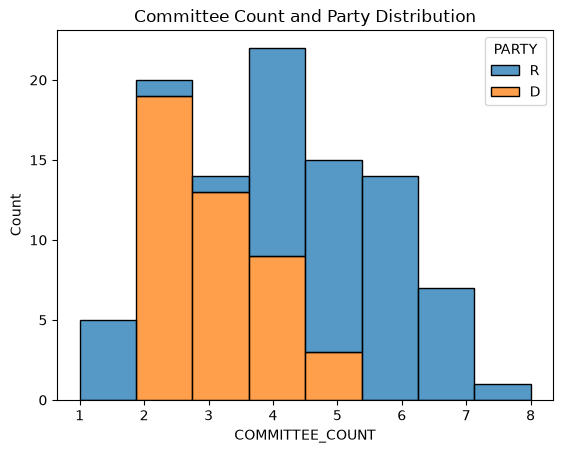

In [11]:
plt.title('Committee Count and Party Distribution')
sns.histplot(data=repsData, x="COMMITTEE_COUNT", bins=8, hue="PARTY", multiple="stack")
plt.show();

In [12]:
print('DISTANCE AVERAGES')
print()

dAVG = sum(repsData['DISTANCE'])/len(repsData)
print(F"Average: {dAVG}")

party_averages = repsData.groupby('PARTY')['DISTANCE'].mean()

print(f"Republican Average : {party_averages.get('R', 0)}")
print(f"Democrat Average:   {party_averages.get('D', 0)}")

DISTANCE AVERAGES

Average: 99.08163265306122
Republican Average : 114.72222222222223
Democrat Average:   79.88636363636364


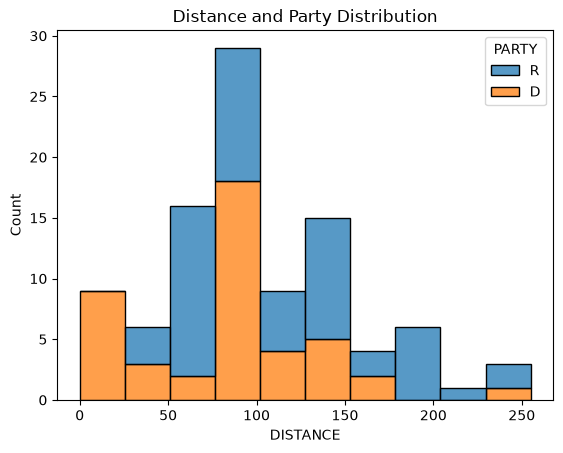

In [13]:
plt.title('Distance and Party Distribution')
sns.histplot(data=repsData, x="DISTANCE", bins=10, hue="PARTY", multiple="stack")
plt.show();

In [14]:
print('DAYS CLAIMED AVERAGES')
print()

daysAVG = sum(repsData['DAYS_CLAIMED'])/len(repsData)
print(F"Average: {daysAVG}")

party_averages = repsData.groupby('PARTY')['DAYS_CLAIMED'].mean()

print(f"Republican Average : {party_averages.get('R', 0)}")
print(f"Democrat Average:   {party_averages.get('D', 0)}")

DAYS CLAIMED AVERAGES

Average: 102.39795918367346
Republican Average : 97.75925925925925
Democrat Average:   108.0909090909091


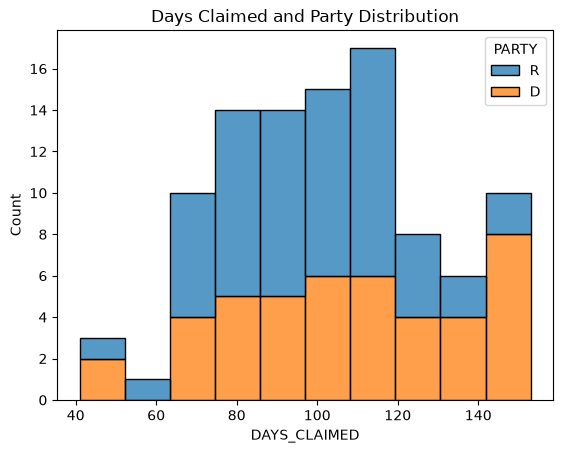

In [15]:
plt.title('Days Claimed and Party Distribution')
sns.histplot(data=repsData, x="DAYS_CLAIMED",bins=10, hue="PARTY", multiple="stack")
plt.show();

In [16]:
print('PER DIEM AVERAGES')
print()

totalAVG = sum(repsData['TOTAL'])/len(repsData)
print(F"Average: {totalAVG}")

party_averages = repsData.groupby('PARTY')['TOTAL'].mean()

print(f"Republican Average : {party_averages.get('R', 0)}")
print(f"Democrat Average:   {party_averages.get('D', 0)}")

PER DIEM AVERAGES

Average: 11898.744897959185
Republican Average : 12159.87962962963
Democrat Average:   11578.261363636364


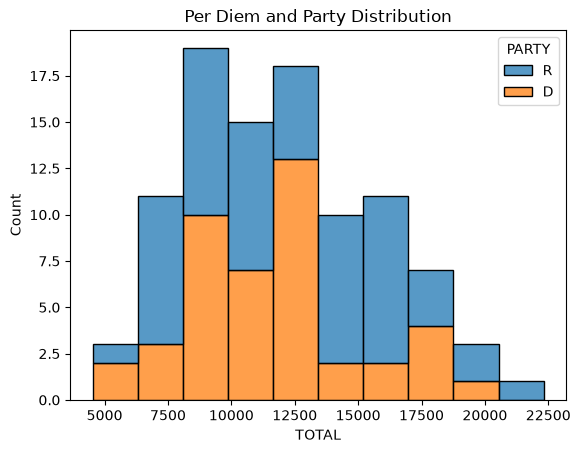

In [17]:
plt.title('Per Diem and Party Distribution')
sns.histplot(data=repsData, x="TOTAL", bins=10, hue="PARTY", multiple="stack")
plt.show();

In [18]:
print('PER DIEM / DAY AVERAGES')
print()

pddAVG = sum(repsData['PER_DIEM/DAY'])/len(repsData)
print(F"Average: {pddAVG}")

party_averages = round(repsData.groupby('PARTY')['PER_DIEM/DAY'].mean(), 2)

print(f"Republican Average : {party_averages.get('R', 0)}")
print(f"Democrat Average:   {party_averages.get('D', 0)}")

PER DIEM / DAY AVERAGES

Average: 116.45142857142856
Republican Average : 122.53
Democrat Average:   109.0


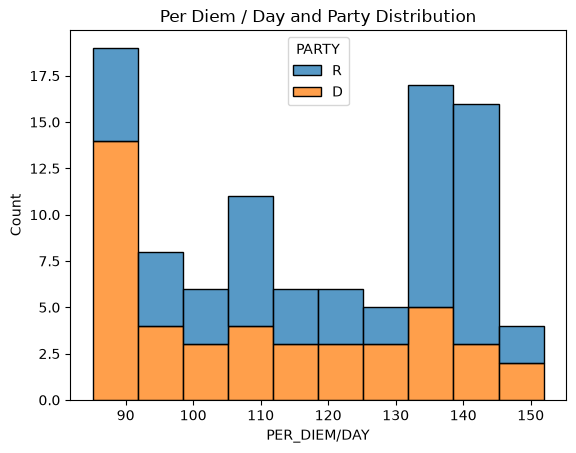

In [19]:
plt.title('Per Diem / Day and Party Distribution')
sns.histplot(data=repsData, x="PER_DIEM/DAY", bins=10, hue="PARTY", multiple="stack")
plt.show();

## Graphs and Relationships

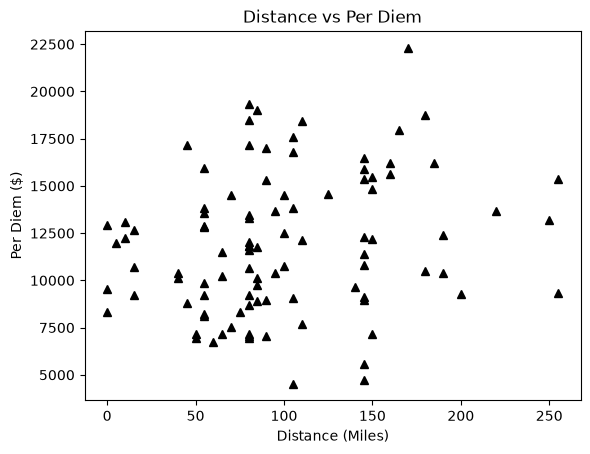

In [20]:
plt.title('Distance vs Per Diem')
plt.xlabel('Distance (Miles)')
plt.ylabel('Per Diem ($)')

plt.plot(distance, perDiem, 'k^');

As seen in the graph, there is a slight positive correlation between per diem and distance. Relationship seems to be fairly linear.

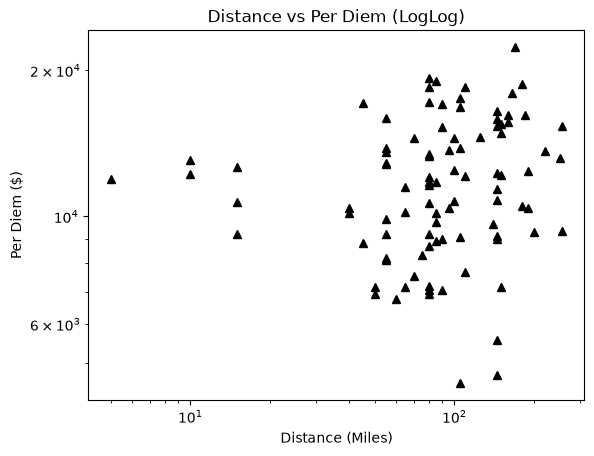

In [21]:
plt.title('Distance vs Per Diem (LogLog)')
plt.xlabel('Distance (Miles)')
plt.ylabel('Per Diem ($)')

plt.loglog(distance, perDiem, 'k^');

The log-log relationship seems to create a worse fit

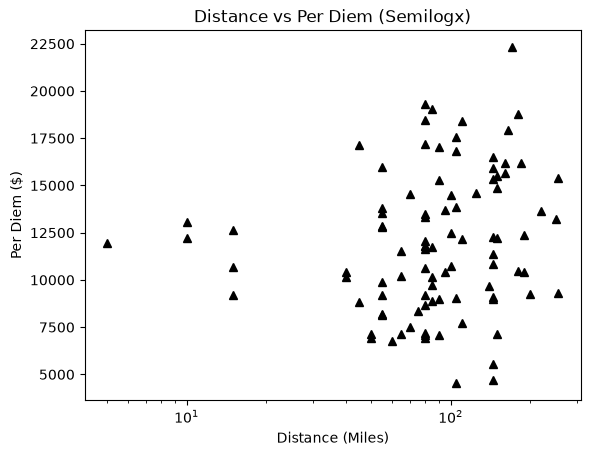

In [22]:
plt.title('Distance vs Per Diem (Semilogx)')
plt.xlabel('Distance (Miles)')
plt.ylabel('Per Diem ($)')

plt.semilogx(distance, perDiem, 'k^');

The semilogx relationship also seems to create a worse fit.

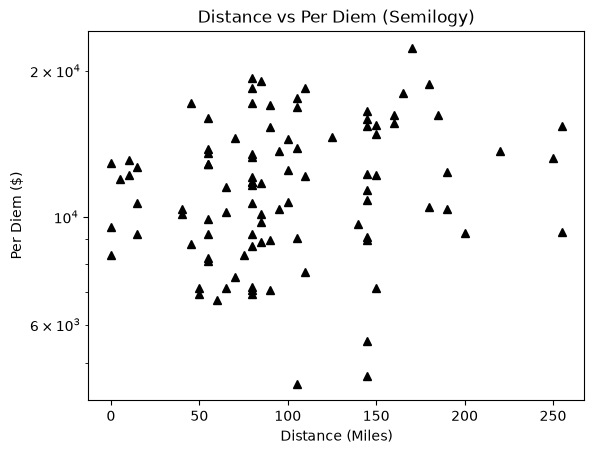

In [23]:
plt.title('Distance vs Per Diem (Semilogy)')
plt.xlabel('Distance (Miles)')
plt.ylabel('Per Diem ($)')

plt.semilogy(distance, perDiem, 'k^');

Semilogy fit also seems worse.

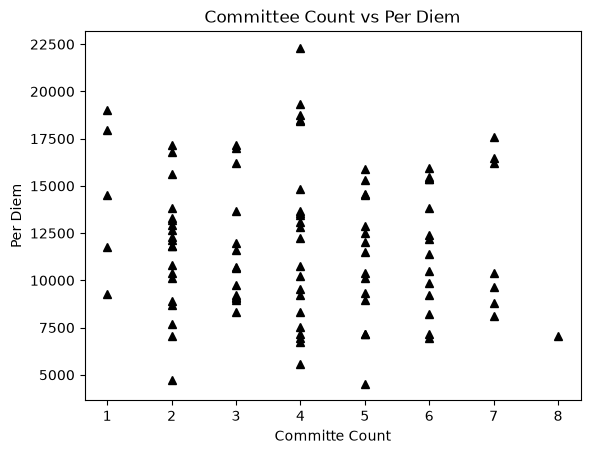

In [24]:
plt.title('Committee Count vs Per Diem')
plt.xlabel('Committe Count')
plt.ylabel('Per Diem')

plt.plot(committeeCount, perDiem, 'k^');

It also appears that there is no significant trend with committee count and the total per diem, if any a slight negative correlation.

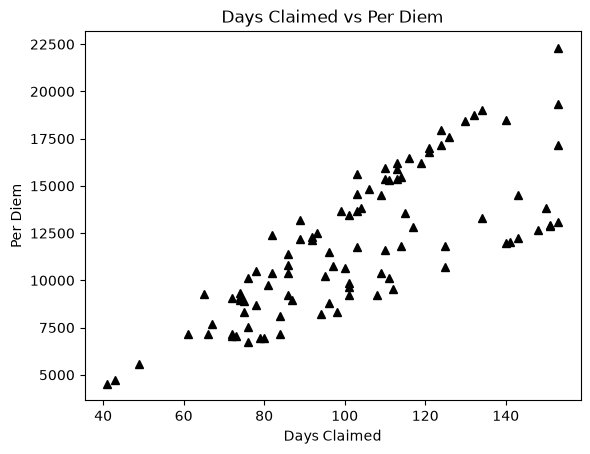

In [25]:
plt.title('Days Claimed vs Per Diem')
plt.xlabel('Days Claimed')
plt.ylabel('Per Diem')

plt.plot(daysClaimed, perDiem, 'k^');

There is a medium positive correlation between days claimed and total per diem.

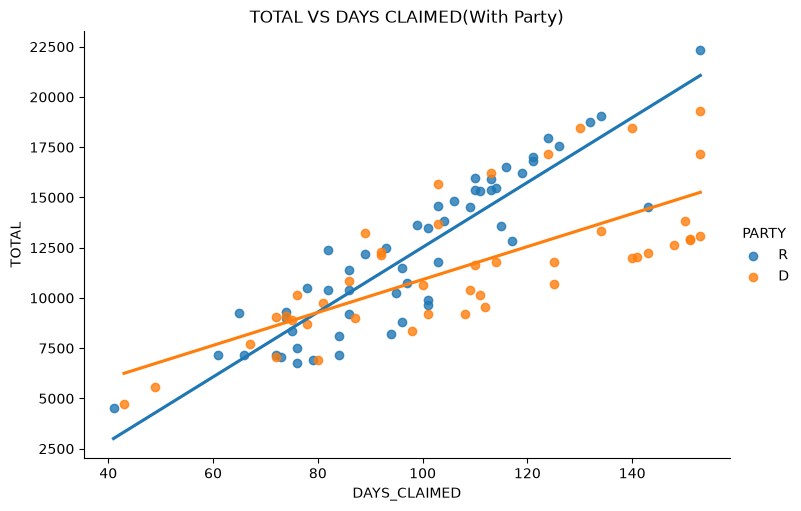

In [26]:
sns.lmplot(
    data=repsData,
    x="DAYS_CLAIMED",
    y="TOTAL",
    hue='PARTY', # You can get any of the Committees my changing the index
    ci=None,        
    height=5,
    aspect=1.5
)
plt.title('TOTAL VS DAYS CLAIMED(With Party)')
plt.show()

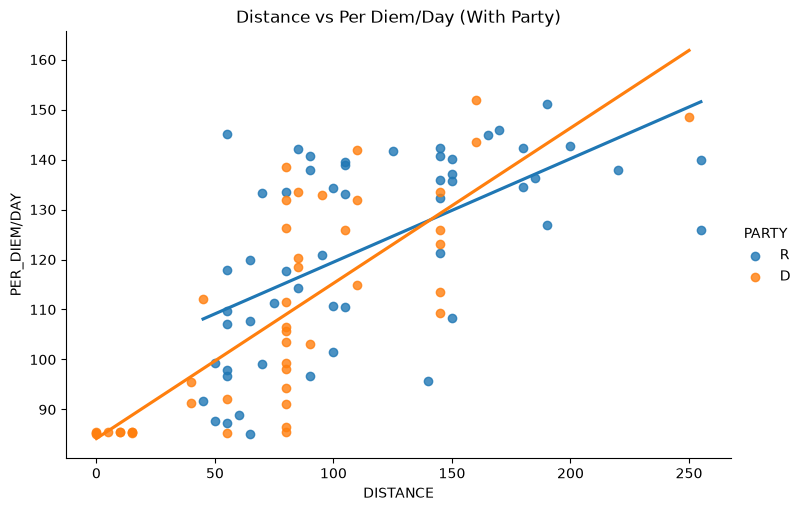

In [27]:
sns.lmplot(
    data=repsData,
    x="DISTANCE",
    y="PER_DIEM/DAY",
    hue='PARTY', # You can get any of the Committees my changing the index
    ci=None,        
    height=5,
    aspect=1.5
)
plt.title('Distance vs Per Diem/Day (With Party)')
plt.show()

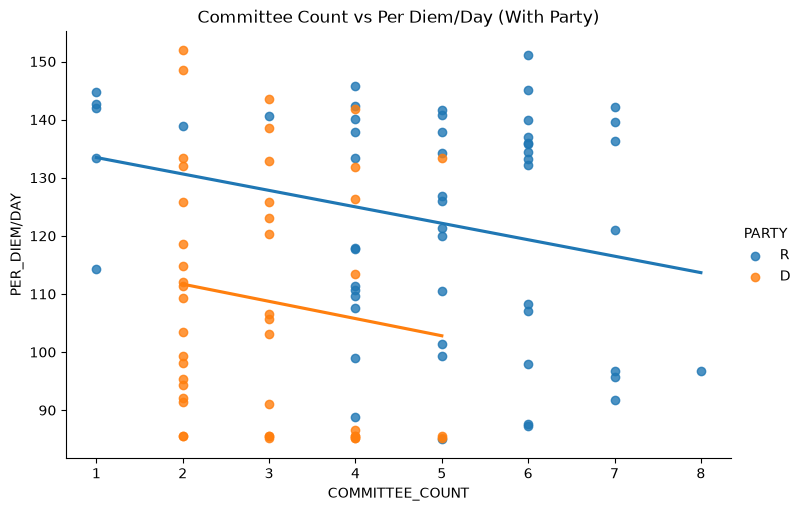

In [28]:
sns.lmplot(
    data=repsData,
    x="COMMITTEE_COUNT",
    y="PER_DIEM/DAY",
    hue='PARTY', # You can get any of the Committees my changing the index
    ci=None,        
    height=5,
    aspect=1.5
)
plt.title('Committee Count vs Per Diem/Day (With Party)')
plt.show()

## Models

In [29]:
#Multiple Linear Regression Full Model

formula = "TOTAL ~ DAYS_CLAIMED + DISTANCE + PARTY + COMMITTEE_COUNT +" + " + ".join(f"Q('{c}')" for c in committee_names)

m_full = smf.ols(formula, data=repsData).fit()

In [30]:
print(m_full.summary())

                            OLS Regression Results                            
Dep. Variable:                  TOTAL   R-squared:                       0.922
Model:                            OLS   Adj. R-squared:                  0.833
Method:                 Least Squares   F-statistic:                     10.29
Date:                Thu, 05 Nov 2026   Prob (F-statistic):           3.27e-13
Time:                        22:38:17   Log-Likelihood:                -818.29
No. Observations:                  98   AIC:                             1743.
Df Residuals:                      45   BIC:                             1880.
Df Model:                          52                                         
Covariance Type:            nonrobust                                         
                                                                coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------

In [31]:
#Full Model

formula = "TOTAL ~ DAYS_CLAIMED + DISTANCE + PARTY + COMMITTEE_COUNT"

m = smf.ols(formula, data=repsData).fit()

In [32]:
print(m.summary())

                            OLS Regression Results                            
Dep. Variable:                  TOTAL   R-squared:                       0.806
Model:                            OLS   Adj. R-squared:                  0.798
Method:                 Least Squares   F-statistic:                     96.62
Date:                Thu, 05 Nov 2026   Prob (F-statistic):           2.91e-32
Time:                        22:38:17   Log-Likelihood:                -863.19
No. Observations:                  98   AIC:                             1736.
Df Residuals:                      93   BIC:                             1749.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept       -3620.5947    951.836     

In [33]:
# Total -Party

formula = "TOTAL ~ DAYS_CLAIMED + DISTANCE + COMMITTEE_COUNT"

m1 = smf.ols(formula, data=repsData).fit()

In [34]:
# - Committe Count

formula = "TOTAL ~ DAYS_CLAIMED + DISTANCE"

m2 = smf.ols(formula, data=repsData).fit()

In [35]:
# -Party

formula = "TOTAL ~ DAYS_CLAIMED"

m3 = smf.ols(formula, data=repsData).fit()

#### Regression Results of our Models

In [36]:
print(m1.summary())

                            OLS Regression Results                            
Dep. Variable:                  TOTAL   R-squared:                       0.783
Model:                            OLS   Adj. R-squared:                  0.776
Method:                 Least Squares   F-statistic:                     113.3
Date:                Thu, 05 Nov 2026   Prob (F-statistic):           4.16e-31
Time:                        22:38:17   Log-Likelihood:                -868.61
No. Observations:                  98   AIC:                             1745.
Df Residuals:                      94   BIC:                             1756.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept       -3822.8099    998.483     

In [37]:
print(m2.summary())

                            OLS Regression Results                            
Dep. Variable:                  TOTAL   R-squared:                       0.783
Model:                            OLS   Adj. R-squared:                  0.779
Method:                 Least Squares   F-statistic:                     171.5
Date:                Thu, 05 Nov 2026   Prob (F-statistic):           2.94e-32
Time:                        22:38:17   Log-Likelihood:                -868.66
No. Observations:                  98   AIC:                             1743.
Df Residuals:                      95   BIC:                             1751.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept    -3967.0459    881.439     -4.501   

In [38]:
print(m3.summary())

                            OLS Regression Results                            
Dep. Variable:                  TOTAL   R-squared:                       0.584
Model:                            OLS   Adj. R-squared:                  0.580
Method:                 Least Squares   F-statistic:                     135.0
Date:                Thu, 05 Nov 2026   Prob (F-statistic):           5.19e-20
Time:                        22:38:17   Log-Likelihood:                -900.52
No. Observations:                  98   AIC:                             1805.
Df Residuals:                      96   BIC:                             1810.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept      954.4483    972.331      0.982   

#### Some Partial F-Tests

In [39]:
sm.stats.anova_lm(m1, m)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,94.0,2.866594e+08,0.0,NaN,NaN,NaN
1,93.0,2.566592e+08,1.0,3.000021e+07,10.870523,0.001385


In [40]:
sm.stats.anova_lm(m2, m1)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,95.0,2.869579e+08,0.0,NaN,NaN,NaN
1,94.0,2.866594e+08,1.0,298437.167804,0.097862,0.755103


In [41]:
sm.stats.anova_lm(m3, m2)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,96.0,5.498301e+08,0.0,NaN,NaN,NaN
1,95.0,2.869579e+08,1.0,2.628723e+08,87.02625,4.496996e-15


## Proposed Per Diem Allowances and Potential Savings

Using our selected multiple linear regression model (m2) based upon days claimed and distance, we calculate predicted annual per diem amounts for each representative and compare these predictions with their actual 2025 claims.

We now can evaluate a hypothetical policy in which each representative's annual reimbursement is capped at their model-predicted amount. This allows us to estimate how much spending could have been avoided in 2025 if our proposed limits had been applied.

### Declaration of Variables Used Below
| Symbol | Variable | Units |
|:---:|:---|:---:|
| $P_i$ | Historical annual per diem payment for representative $i$ | USD |
| $\hat{P}_i$ | Model-estimated annual per diem allowance | USD |
| $D_i$ | Approximate distance from Madison for representative $i$ | Miles |
| $d_i$ | Number of days claimed for representative $i$ | Days |
| $S_i$ | Savings for representative $i$ (from eliminating positive residuals) | USD |
| $S_{\text{total}}$ | Total savings from our proposed change | USD |


### Our Proposed Model (With Coefficients From Model m2 Above):

\begin{aligned}
\hat{P}_i = -3967.0459 + 125.4870d_i + 30.4414D_i, 
\end{aligned}

The potential savings are calculated as:

$$
S_i = \max(0, P_i - \max(0,\hat{P}_i))
$$

Therefore, the total potential savings are:

$$
\boxed{S_{\text{total}} = \sum_{i=1}^{n} S_i}
$$

In [42]:
#Apply the regression model to each representative's 2025 data
repsData['PREDICTED_PER_DIEM'] = m2.predict(repsData)

#setting the proposed cap equal to the predicted diem (min of 0)
repsData['PROPOSED_CAP'] = repsData['PREDICTED_PER_DIEM'].clip(lower = 0) #ensuring nobody gets negative per-diem allowance (shouldn't happen)

#Calculating the hypothetical spending if 2025 claims were subject to the cap
repsData['CAPPED_SPENDING'] = np.minimum( #selects which value between total spending and proposed spending is smaller
    repsData['TOTAL'],
    repsData['PROPOSED_CAP']
)

#Calculating the savings for each representative
repsData['POTENTIAL_SAVINGS'] = (
    repsData['TOTAL'] - repsData['CAPPED_SPENDING']
)

#Comparing the historical spending with our proposed system
actual_total = repsData['TOTAL'].sum() #total spending in 2025
predicted_total = repsData['PREDICTED_PER_DIEM'].sum() #should be same as prev line
capped_total = repsData['CAPPED_SPENDING'].sum() #hypothetical spending with our cap introduced
total_savings = repsData['POTENTIAL_SAVINGS'].sum() #hypothetical savings

print("\n2025 SPENDING COMPARISON")
print(f"Actual 2025 Spending: ${actual_total:,.2f}")
print(f"Total Model Predictions: ${predicted_total:,.2f}")
print(f"Hypothetical Capped Spending: ${capped_total:,.2f}")
print(f"Potential Savings: ${total_savings:,.2f}")
print(f"Percent Reduction: {100 * total_savings / actual_total:.2f}%")

#Show representatives with the largest potential savings
print("\nRepresentatives with Largest Savings:")

display(
    repsData[[
        'NAME', 'DISTANCE', 'COMMITTEE_COUNT',
        'TOTAL', 'PREDICTED_PER_DIEM', 'POTENTIAL_SAVINGS'
    ]] #Grabbing the repsData info and sorting by potential savings
    .sort_values(by='POTENTIAL_SAVINGS', ascending=False)
    .head(10)
    .round(2) #rounding to two decimal places bc its money
)



2025 SPENDING COMPARISON
Actual 2025 Spending: $1,166,077.00
Total Model Predictions: $1,166,077.00
Hypothetical Capped Spending: $1,097,974.24
Potential Savings: $68,102.76
Percent Reduction: 5.84%

Representatives with Largest Savings:


,NAME,DISTANCE,COMMITTEE_COUNT,TOTAL,PREDICTED_PER_DIEM,POTENTIAL_SAVINGS
30,"August, Tyler",55,6,15956.5,11510.80,4445.70
38,"Dallman, Alex",85,1,19034.5,15435.72,3598.78
8,"Prado, Priscilla",80,3,17185.5,14028.65,3156.85
62,"Wittke, Robert",90,3,17014.5,13956.60,3057.90
63,"McGuire, Tip",110,4,18436.0,15694.81,2741.19
40,"Kurtz, Tony",70,1,14533.5,11841.93,2691.57
58,"Brooks, Rob",90,5,15304.5,12701.73,2602.77
54,"Gustafson, Nate",105,7,17581.0,15040.66,2540.34
18,"Clancy, Ryan",80,4,18468.0,16036.44,2431.56
31,"Nedweski, Amanda",105,2,16811.5,14413.22,2398.28
